Saving regresion_lineal_simple_datos_corregidos.xlsx to regresion_lineal_simple_datos_corregidos (1).xlsx
['Fecha', 'Estacion', 'Sensor', 'Sensor_corregido']


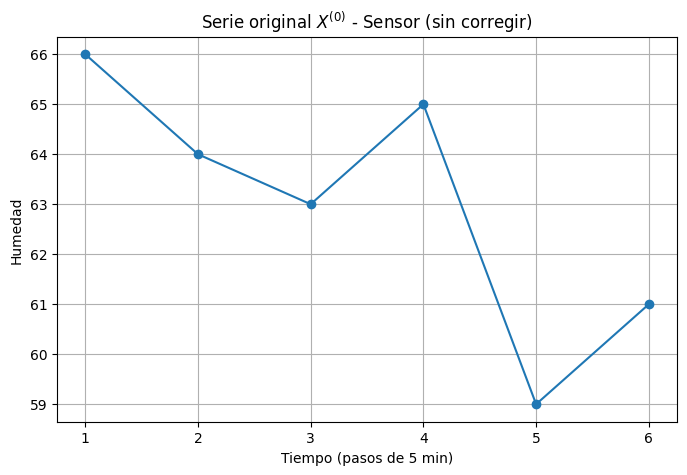

Serie original X^(0) - Sensor (sin corregir):
[66. 64. 63. 65. 59. 61.]



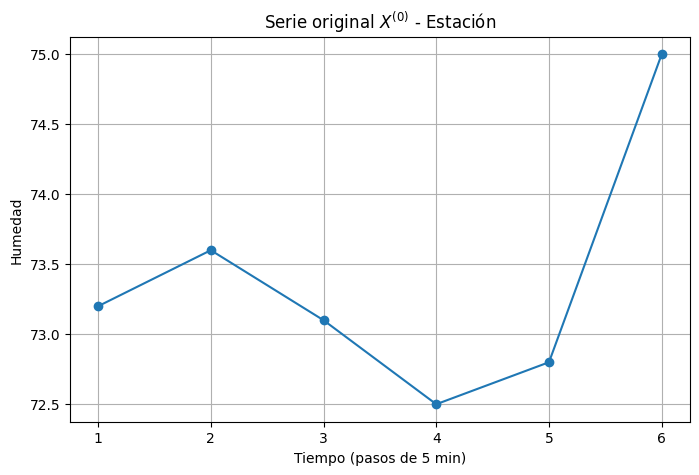

Serie original X^(0) - Estación:
[73.2 73.6 73.1 72.5 72.8 75. ]



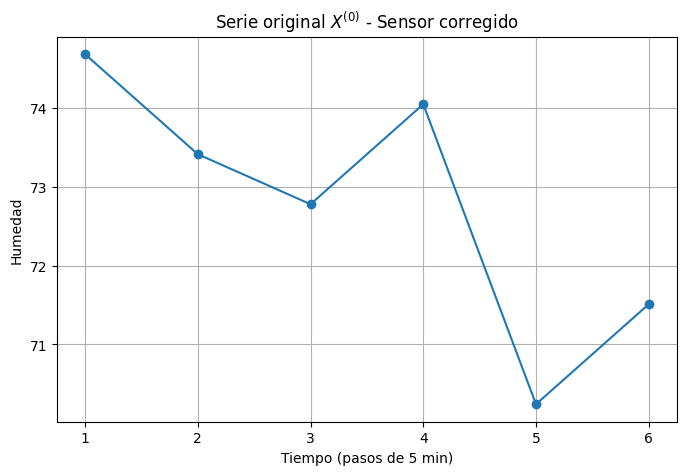

Serie original X^(0) - Sensor corregido:
[74.682951 73.414177 72.779791 74.048564 70.242244 71.511017]



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ---------------------------------------------------------
# 1) Subir y leer el archivo Excel
# ---------------------------------------------------------
subido = files.upload()
nombre_archivo = list(subido.keys())[0]
df = pd.read_excel(nombre_archivo)
print(df.columns.tolist())

col_fecha     = "Fecha"
col_sensor    = "Sensor"
col_ref       = "Estacion"
col_corregido = "Sensor_corregido"

n = 6   # None = todos los datos; o un número (ej. 10) para ventana corta

# ---------------------------------------------------------
# 2) Limpieza
# ---------------------------------------------------------
datos = df[[col_fecha, col_ref, col_sensor, col_corregido]].copy()
datos[col_fecha] = pd.to_datetime(datos[col_fecha], errors="coerce")
for c in [col_ref, col_sensor, col_corregido]:
    datos[c] = pd.to_numeric(datos[c], errors="coerce")
datos = datos.dropna().sort_values(col_fecha).reset_index(drop=True)

if n:
    datos = datos.head(n)

# ---------------------------------------------------------
# 3) Series originales X^(0)
# ---------------------------------------------------------
series = {
    "Sensor (sin corregir)": datos[col_sensor].to_numpy(dtype=float),
    "Estación":              datos[col_ref].to_numpy(dtype=float),
    "Sensor corregido":      datos[col_corregido].to_numpy(dtype=float),
}

# Índice temporal (cada paso = 5 min)
k = np.arange(1, len(datos) + 1)

# ---------------------------------------------------------
# 4) Una gráfica por cada serie
# ---------------------------------------------------------
for nombre, X0 in series.items():
    plt.figure(figsize=(8, 5))
    plt.plot(k, X0, marker='o')

    plt.xlabel('Tiempo (pasos de 5 min)')
    plt.ylabel('Humedad')
    plt.title(rf'Serie original $X^{{(0)}}$ - {nombre}')
    plt.xticks(k)
    plt.grid(True)

    plt.show()

    print(f"Serie original X^(0) - {nombre}:")
    print(X0)
    print()

Serie original X^(0) - Sensor (sin corregir):
[66. 64. 63. 65. 59. 61.]

Serie acumulada X^(1) (AGO) - Sensor (sin corregir):
[ 66. 130. 193. 258. 317. 378.]



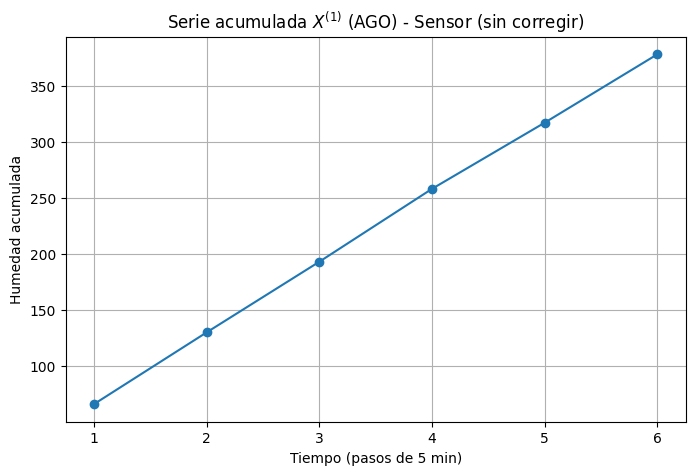

Serie original X^(0) - Estación:
[73.2 73.6 73.1 72.5 72.8 75. ]

Serie acumulada X^(1) (AGO) - Estación:
[ 73.2 146.8 219.9 292.4 365.2 440.2]



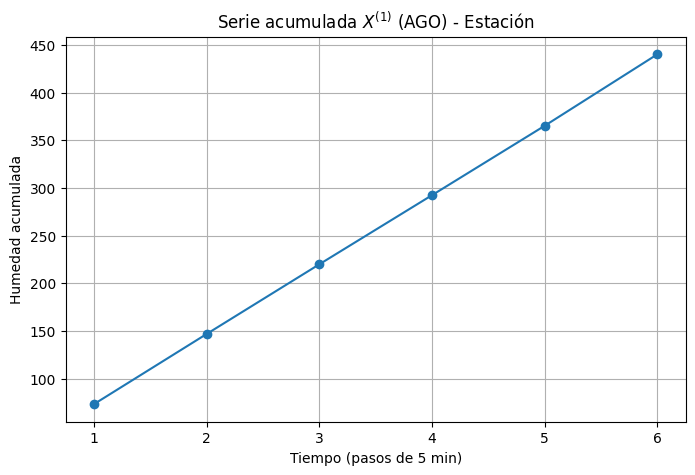

Serie original X^(0) - Sensor corregido:
[74.682951 73.414177 72.779791 74.048564 70.242244 71.511017]

Serie acumulada X^(1) (AGO) - Sensor corregido:
[ 74.682951 148.097128 220.876919 294.925483 365.167727 436.678745]



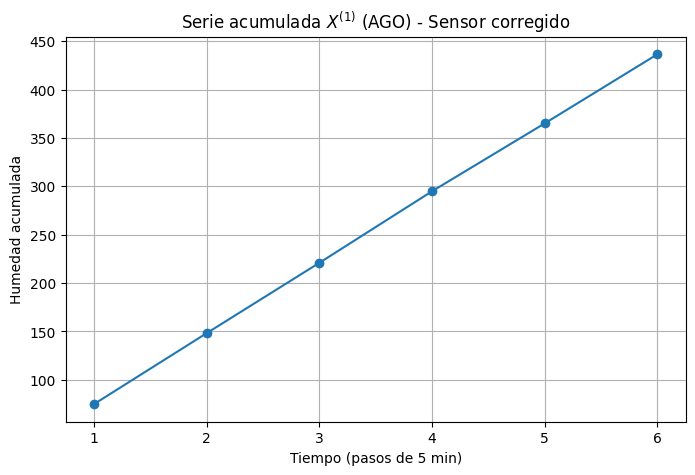

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Operación AGO (usa `series` y `k` de la celda anterior)
#
# x^(1)(k) = sumatoria desde i=1 hasta k de x^(0)(i)
# ---------------------------------------------------------
series_ago = {nombre: np.cumsum(X0) for nombre, X0 in series.items()}

for nombre, X1 in series_ago.items():
    print(f"Serie original X^(0) - {nombre}:")
    print(series[nombre])
    print(f"\nSerie acumulada X^(1) (AGO) - {nombre}:")
    print(X1)
    print()

    plt.figure(figsize=(8, 5))
    plt.plot(k, X1, marker='o')

    plt.xlabel('Tiempo (pasos de 5 min)')
    plt.ylabel('Humedad acumulada')
    plt.title(rf'Serie acumulada $X^{{(1)}}$ (AGO) - {nombre}')
    plt.xticks(k)
    plt.grid(True)

    plt.show()

In [ ]:
import numpy as np

# ---------------------------------------------------------
# Secuencia media generada Z^(1) (usa `series` y `series_ago` de celdas anteriores)
#
# z^(1)(k) = 0.5*x^(1)(k) + 0.5*x^(1)(k-1)
#
# k = 2, 3, ..., n
# ---------------------------------------------------------

series_z = {nombre: 0.5 * (X1[1:] + X1[:-1]) for nombre, X1 in series_ago.items()}

for nombre in series:
    print(f"===== {nombre} =====")

    print("Serie original X^(0):")
    print(series[nombre])

    print("\nSerie acumulada X^(1):")
    print(series_ago[nombre])

    print("\nSecuencia media generada Z^(1):")
    print(series_z[nombre])
    print()

===== Sensor (sin corregir) =====
Serie original X^(0):
[66. 64. 63. 65. 59. 61.]

Serie acumulada X^(1):
[ 66. 130. 193. 258. 317. 378.]

Secuencia media generada Z^(1):
[ 98.  161.5 225.5 287.5 347.5]

===== Estación =====
Serie original X^(0):
[73.2 73.6 73.1 72.5 72.8 75. ]

Serie acumulada X^(1):
[ 73.2 146.8 219.9 292.4 365.2 440.2]

Secuencia media generada Z^(1):
[110.   183.35 256.15 328.8  402.7 ]

===== Sensor corregido =====
Serie original X^(0):
[74.682951 73.414177 72.779791 74.048564 70.242244 71.511017]

Serie acumulada X^(1):
[ 74.682951 148.097128 220.876919 294.925483 365.167727 436.678745]

Secuencia media generada Z^(1):
[111.390039 184.487023 257.901201 330.046605 400.923236]



In [ ]:
import numpy as np

# ---------------------------------------------------------
# Construcción de las matrices Y y B
# (usa `series` y `series_z` de celdas anteriores)
#
# Y = [x^(0)(2), ..., x^(0)(n)]^T
# B = [-z^(1)(k), 1]  para k = 2, ..., n
# ---------------------------------------------------------

series_Y = {}
series_B = {}

for nombre in series:
    X0 = series[nombre]
    Z1 = series_z[nombre]

    series_Y[nombre] = X0[1:].reshape(-1, 1)
    series_B[nombre] = np.column_stack((-Z1, np.ones(len(Z1))))

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

for nombre in series:
    print(f"===== {nombre} =====")

    print("Matriz Y:")
    print(series_Y[nombre])

    print("\nMatriz B:")
    print(series_B[nombre])
    print()

===== Sensor (sin corregir) =====
Matriz Y:
[[64.]
 [63.]
 [65.]
 [59.]
 [61.]]

Matriz B:
[[ -98.     1. ]
 [-161.5    1. ]
 [-225.5    1. ]
 [-287.5    1. ]
 [-347.5    1. ]]

===== Estación =====
Matriz Y:
[[73.6]
 [73.1]
 [72.5]
 [72.8]
 [75. ]]

Matriz B:
[[-110.      1.  ]
 [-183.35    1.  ]
 [-256.15    1.  ]
 [-328.8     1.  ]
 [-402.7     1.  ]]

===== Sensor corregido =====
Matriz Y:
[[73.414177]
 [72.779791]
 [74.048564]
 [70.242244]
 [71.511017]]

Matriz B:
[[-111.390039    1.      ]
 [-184.487023    1.      ]
 [-257.901201    1.      ]
 [-330.046605    1.      ]
 [-400.923236    1.      ]]



In [ ]:
import numpy as np

# ---------------------------------------------------------
# Estimación de los parámetros a y b
# (usa `series_B` y `series_Y` de celdas anteriores)
#
# [a b]^T = (B^T B)^(-1) B^T Y
# ---------------------------------------------------------

np.set_printoptions(suppress=True, precision=6)

series_params = {}

for nombre in series:
    B = series_B[nombre]
    Y = series_Y[nombre]

    parametros = np.linalg.inv(B.T @ B) @ B.T @ Y

    a = parametros[0, 0]
    b = parametros[1, 0]
    series_params[nombre] = (a, b)

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

for nombre in series:
    a, b = series_params[nombre]

    print(f"===== {nombre} =====")
    print("Matriz B:")
    print(series_B[nombre])

    print("\nMatriz Y:")
    print(series_Y[nombre])

    print("\nParámetros estimados:")
    print("a =", a)
    print("b =", b)
    print()

===== Sensor (sin corregir) =====
Matriz B:
[[ -98.     1. ]
 [-161.5    1. ]
 [-225.5    1. ]
 [-287.5    1. ]
 [-347.5    1. ]]

Matriz Y:
[[64.]
 [63.]
 [65.]
 [59.]
 [61.]]

Parámetros estimados:
a = 0.01597174230208079
b = 65.9776702756661

===== Estación =====
Matriz B:
[[-110.      1.  ]
 [-183.35    1.  ]
 [-256.15    1.  ]
 [-328.8     1.  ]
 [-402.7     1.  ]]

Matriz Y:
[[73.6]
 [73.1]
 [72.5]
 [72.8]
 [75. ]]

Parámetros estimados:
a = -0.003435391931883765
b = 72.51985258705142

===== Sensor corregido =====
Matriz B:
[[-111.390039    1.      ]
 [-184.487023    1.      ]
 [-257.901201    1.      ]
 [-330.046605    1.      ]
 [-400.923236    1.      ]]

Matriz Y:
[[73.414177]
 [72.779791]
 [74.048564]
 [70.242244]
 [71.511017]]

Parámetros estimados:
a = 0.008746576853882476
b = 74.64658839596729



In [ ]:
import numpy as np

# ---------------------------------------------------------
# Ecuación (11) del paper
# (usa `series` y `series_params` de celdas anteriores)
#
# x_hat^(1)(k+1) = [x^(0)(1) - b/a] * exp(-a*k) + b/a
# ---------------------------------------------------------

n_pred = 0   # pasos futuros a pronosticar (cada paso = 5 min); 0 = solo ajuste

def x1_predicha(k, x0_1, a, b):
    return (x0_1 - b/a) * np.exp(-a*k) + b/a

series_X1_hat = {}

for nombre, X0 in series.items():
    a, b = series_params[nombre]
    x0_1 = X0[0]                      # primer valor de la serie original

    # k = 0, 1, 2, ..., n-1 (+ pasos futuros si n_pred > 0)
    k_est = np.arange(0, len(X0) + n_pred)

    series_X1_hat[nombre] = np.array([x1_predicha(i, x0_1, a, b) for i in k_est])

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

for nombre in series:
    a, b = series_params[nombre]

    print(f"===== {nombre} =====")
    print("Parámetro a =", a)
    print("Parámetro b =", b)

    print("\nValores estimados de X^(1):")
    for i, valor in enumerate(series_X1_hat[nombre], start=1):
        print(f"x_hat^(1)({i}) = {valor:.6f}")
    print()

===== Sensor (sin corregir) =====
Parámetro a = 0.01597174230208079
Parámetro b = 65.9776702756661

Valores estimados de X^(1):
x_hat^(1)(1) = 66.000000
x_hat^(1)(2) = 130.407814
x_hat^(1)(3) = 193.795094
x_hat^(1)(4) = 256.178011
x_hat^(1)(5) = 317.572478
x_hat^(1)(6) = 377.994159

===== Estación =====
Parámetro a = -0.003435391931883765
Parámetro b = 72.51985258705142

Valores estimados de X^(1):
x_hat^(1)(1) = 73.200000
x_hat^(1)(2) = 146.096466
x_hat^(1)(3) = 219.243790
x_hat^(1)(4) = 292.642836
x_hat^(1)(5) = 366.294470
x_hat^(1)(6) = 440.199561

===== Sensor corregido =====
Parámetro a = 0.008746576853882476
Parámetro b = 74.64658839596729

Valores estimados de X^(1):
x_hat^(1)(1) = 74.682951
x_hat^(1)(2) = 148.353666
x_hat^(1)(3) = 221.382824
x_hat^(1)(4) = 293.776013
x_hat^(1)(5) = 365.538770
x_hat^(1)(6) = 436.676586



In [ ]:
import numpy as np

# ---------------------------------------------------------
# Ecuación (12) del paper
# (usa `series`, `series_params` y `n_pred` de celdas anteriores)
#
# x_hat^(0)(k+1) = (x^(0)(1) - b/a) * exp(-a*k) * (1 - exp(a))
#
# k = 1, 2, ..., n-1 (+ pasos futuros si n_pred > 0)
# ---------------------------------------------------------

def x0_predicha(k, x0_1, a, b):
    return (x0_1 - b/a) * np.exp(-a*k) * (1 - np.exp(a))

series_X0_hat = {}

for nombre, X0 in series.items():
    a, b = series_params[nombre]
    x0_1 = X0[0]                      # primer valor de la serie original

    k_est = np.arange(1, len(X0) + n_pred)

    X0_hat_restante = np.array([x0_predicha(i, x0_1, a, b) for i in k_est])

    # El primer valor se conserva como condición inicial
    series_X0_hat[nombre] = np.concatenate(([x0_1], X0_hat_restante))

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

for nombre in series:
    a, b = series_params[nombre]

    print(f"===== {nombre} =====")
    print("Parámetro a =", a)
    print("Parámetro b =", b)

    print("\nSerie original:")
    print(series[nombre])

    print("\nSerie estimada mediante la ecuación (12):")
    print(series_X0_hat[nombre])

    print("\nValores individuales:")
    for i, valor in enumerate(series_X0_hat[nombre], start=1):
        print(f"x_hat^(0)({i}) = {valor:.6f}")
    print()

===== Sensor (sin corregir) =====
Parámetro a = 0.01597174230208079
Parámetro b = 65.9776702756661

Serie original:
[66. 64. 63. 65. 59. 61.]

Serie estimada mediante la ecuación (12):
[66.       64.407814 63.38728  62.382917 61.394468 60.42168 ]

Valores individuales:
x_hat^(0)(1) = 66.000000
x_hat^(0)(2) = 64.407814
x_hat^(0)(3) = 63.387280
x_hat^(0)(4) = 62.382917
x_hat^(0)(5) = 61.394468
x_hat^(0)(6) = 60.421680

===== Estación =====
Parámetro a = -0.003435391931883765
Parámetro b = 72.51985258705142

Serie original:
[73.2 73.6 73.1 72.5 72.8 75. ]

Serie estimada mediante la ecuación (12):
[73.2      72.896466 73.147324 73.399046 73.651634 73.905091]

Valores individuales:
x_hat^(0)(1) = 73.200000
x_hat^(0)(2) = 72.896466
x_hat^(0)(3) = 73.147324
x_hat^(0)(4) = 73.399046
x_hat^(0)(5) = 73.651634
x_hat^(0)(6) = 73.905091

===== Sensor corregido =====
Parámetro a = 0.008746576853882476
Parámetro b = 74.64658839596729

Serie original:
[74.682951 73.414177 72.779791 74.048564 70.24224

===== Sensor (sin corregir) =====
X^(0) original:
[66. 64. 63. 65. 59. 61.]

X_hat^(0) estimada:
[66.       64.407814 63.38728  62.382917 61.394468 60.42168 ]

Error porcentual medio (MAPE): 1.7141 %



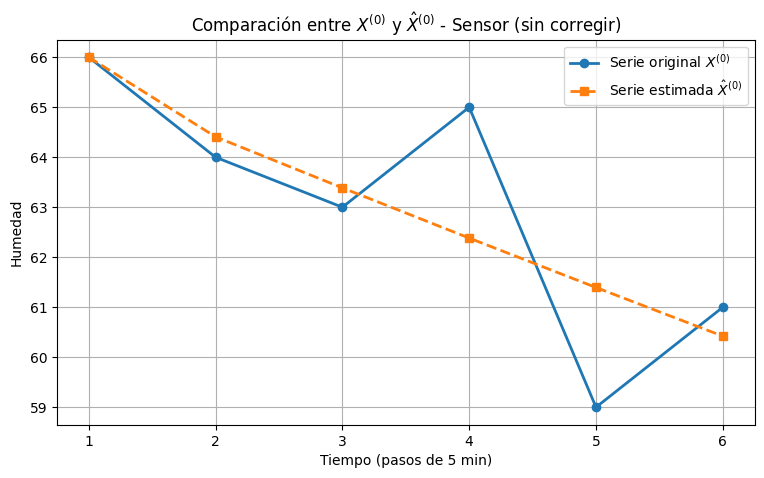

===== Estación =====
X^(0) original:
[73.2 73.6 73.1 72.5 72.8 75. ]

X_hat^(0) estimada:
[73.2      72.896466 73.147324 73.399046 73.651634 73.905091]

Error porcentual medio (MAPE): 0.8151 %



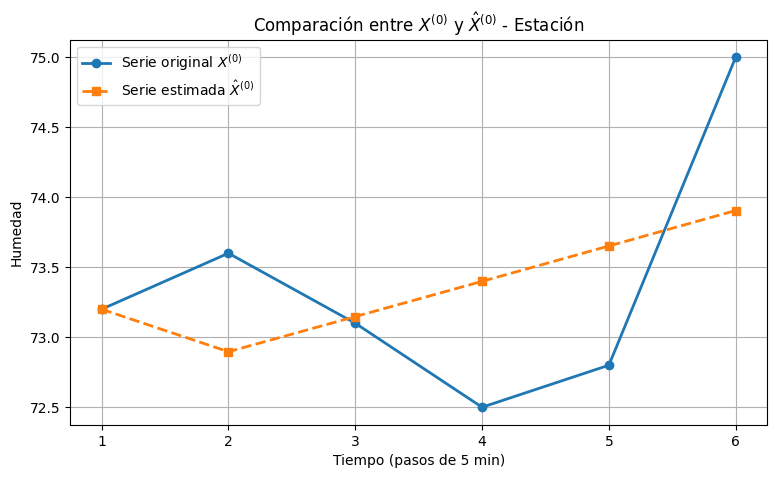

===== Sensor corregido =====
X^(0) original:
[74.682951 73.414177 72.779791 74.048564 70.242244 71.511017]

X_hat^(0) estimada:
[74.682951 73.670715 73.029159 72.393189 71.762757 71.137816]

Error porcentual medio (MAPE): 0.9357 %



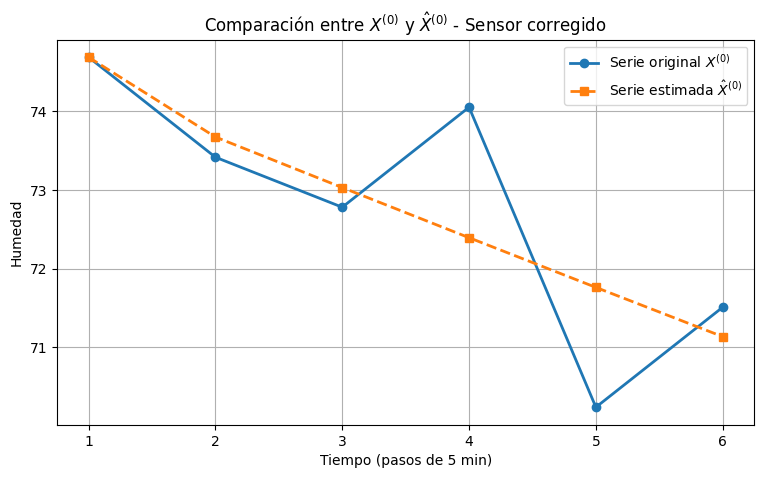

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Comparación X^(0) vs X_hat^(0)
# (usa `series`, `series_X0_hat` y `n_pred` de celdas anteriores)
# ---------------------------------------------------------

for nombre, X0 in series.items():
    X0_hat = series_X0_hat[nombre]

    # Índices temporales (el de la estimada es más largo si n_pred > 0)
    k_real = np.arange(1, len(X0) + 1)
    k_hat  = np.arange(1, len(X0_hat) + 1)

    # -----------------------------------------------------
    # Mostrar valores
    # -----------------------------------------------------
    print(f"===== {nombre} =====")
    print("X^(0) original:")
    print(X0)

    print("\nX_hat^(0) estimada:")
    print(X0_hat)

    # Error porcentual medio sobre los datos reales
    mape = np.mean(np.abs((X0 - X0_hat[:len(X0)]) / X0)) * 100
    print(f"\nError porcentual medio (MAPE): {mape:.4f} %")
    print()

    # -----------------------------------------------------
    # Graficación
    # -----------------------------------------------------
    plt.figure(figsize=(9, 5))

    plt.plot(k_real, X0,
             marker='o',
             linewidth=2,
             label=r'Serie original $X^{(0)}$')

    plt.plot(k_hat, X0_hat,
             marker='s',
             linestyle='--',
             linewidth=2,
             label=r'Serie estimada $\hat{X}^{(0)}$')

    if n_pred > 0:
        plt.axvline(len(X0), color='gray', linestyle=':', label='Inicio pronóstico')

    plt.xlabel('Tiempo (pasos de 5 min)')
    plt.ylabel('Humedad')
    plt.title(rf'Comparación entre $X^{{(0)}}$ y $\hat{{X}}^{{(0)}}$ - {nombre}')

    plt.xticks(k_hat)
    plt.grid(True)
    plt.legend()

    plt.show()

In [ ]:
import numpy as np

# ---------------------------------------------------------
# Ecuaciones (37), (38) y (39): Error, RPE y ARPE
# (usa `series` y `series_X0_hat` de celdas anteriores)
#
# error(k) = x^(0)(k) - x_hat^(0)(k)
# RPE(k)   = |error(k)| / x^(0)(k) * 100
# ARPE     = promedio de RPE(k), excluyendo k = 1 (condición inicial)
# ---------------------------------------------------------

series_error = {}
series_RPE   = {}
series_ARPE  = {}

for nombre, X0 in series.items():
    # Solo se compara sobre los datos reales (se ignoran pasos futuros si n_pred > 0)
    X0_hat = series_X0_hat[nombre][:len(X0)]

    error = X0 - X0_hat                      # Ecuación (37)
    RPE   = np.abs(error) / X0 * 100         # Ecuación (38)
    ARPE  = np.mean(RPE[1:])                 # Ecuación (39)

    series_error[nombre] = error
    series_RPE[nombre]   = RPE
    series_ARPE[nombre]  = ARPE

# ---------------------------------------------------------
# Mostrar resultados
# ---------------------------------------------------------

for nombre, X0 in series.items():
    X0_hat = series_X0_hat[nombre][:len(X0)]

    print(f"===== {nombre} =====")
    print("k\tX0\t\tX0_hat\t\tError\t\tRPE (%)")

    for i in range(len(X0)):
        print(
            f"{i+1}\t"
            f"{X0[i]:.4f}\t"
            f"{X0_hat[i]:.4f}\t"
            f"{series_error[nombre][i]:.4f}\t"
            f"{series_RPE[nombre][i]:.4f}"
        )

    print("\nARPE = {:.4f} %".format(series_ARPE[nombre]))
    print()

# ---------------------------------------------------------
# Resumen comparativo
# ---------------------------------------------------------

print("Resumen ARPE por serie:")
for nombre, valor in series_ARPE.items():
    print(f"  {nombre}: {valor:.4f} %")

===== Sensor (sin corregir) =====
k	X0		X0_hat		Error		RPE (%)
1	66.0000	66.0000	0.0000	0.0000
2	64.0000	64.4078	-0.4078	0.6372
3	63.0000	63.3873	-0.3873	0.6147
4	65.0000	62.3829	2.6171	4.0263
5	59.0000	61.3945	-2.3945	4.0584
6	61.0000	60.4217	0.5783	0.9481

ARPE = 2.0569 %

===== Estación =====
k	X0		X0_hat		Error		RPE (%)
1	73.2000	73.2000	0.0000	0.0000
2	73.6000	72.8965	0.7035	0.9559
3	73.1000	73.1473	-0.0473	0.0647
4	72.5000	73.3990	-0.8990	1.2401
5	72.8000	73.6516	-0.8516	1.1698
6	75.0000	73.9051	1.0949	1.4599

ARPE = 0.9781 %

===== Sensor corregido =====
k	X0		X0_hat		Error		RPE (%)
1	74.6830	74.6830	0.0000	0.0000
2	73.4142	73.6707	-0.2565	0.3494
3	72.7798	73.0292	-0.2494	0.3426
4	74.0486	72.3932	1.6554	2.2355
5	70.2422	71.7628	-1.5205	2.1647
6	71.5110	71.1378	0.3732	0.5219

ARPE = 1.1228 %

Resumen ARPE por serie:
  Sensor (sin corregir): 2.0569 %
  Estación: 0.9781 %
  Sensor corregido: 1.1228 %


===== Sensor (sin corregir) =====
Error:
[ 0.       -0.407814 -0.38728   2.617083 -2.394468  0.57832 ]

RPE (%):
[0.       0.637209 0.61473  4.026282 4.05842  0.948065]

ARPE = 2.0569 %


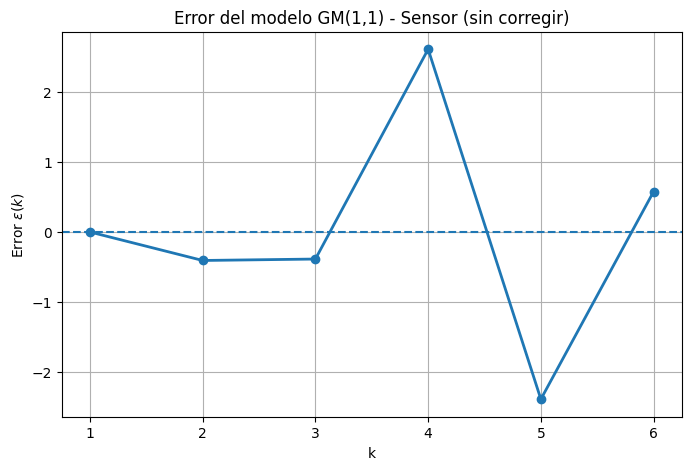

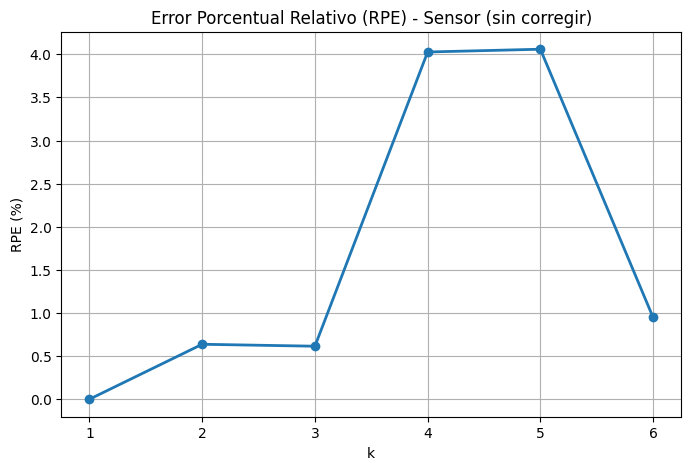

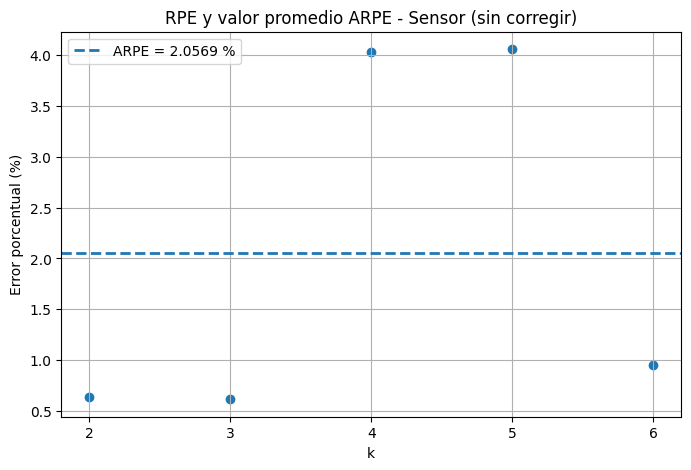

===== Estación =====
Error:
[ 0.        0.703534 -0.047324 -0.899046 -0.851634  1.094909]

RPE (%):
[0.       0.955889 0.064739 1.240063 1.169827 1.459878]

ARPE = 0.9781 %


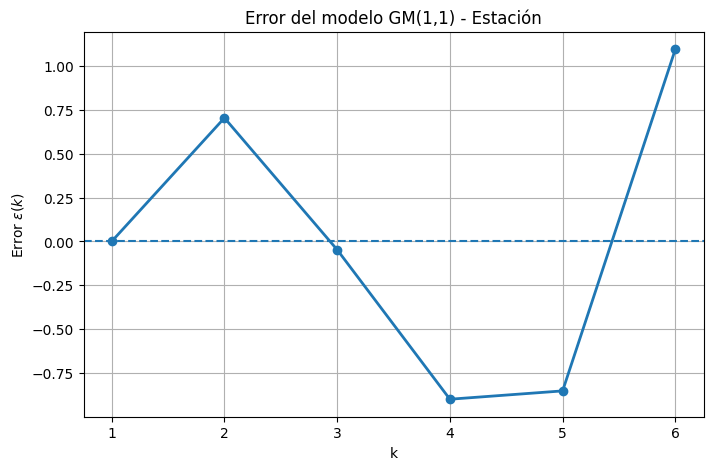

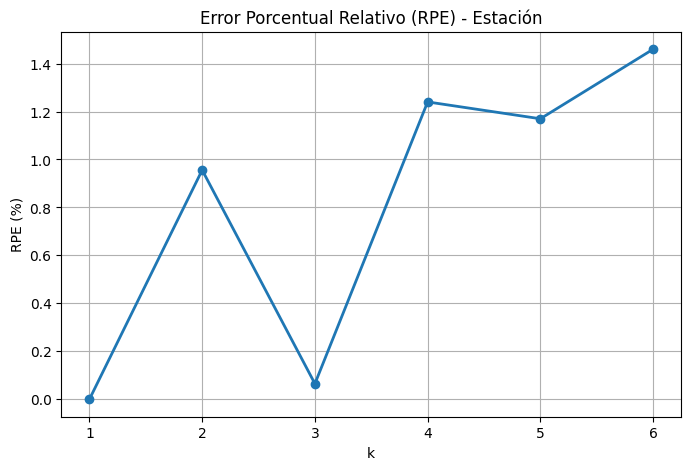

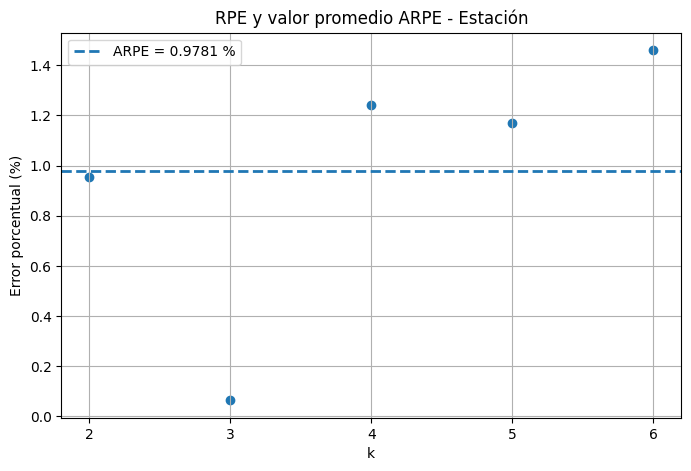

===== Sensor corregido =====
Error:
[ 0.       -0.256538 -0.249368  1.655375 -1.520513  0.373202]

RPE (%):
[0.       0.349439 0.342633 2.235527 2.16467  0.52188 ]

ARPE = 1.1228 %


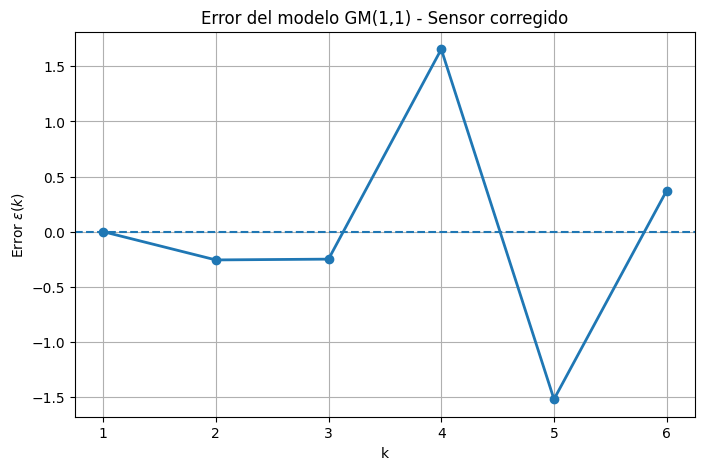

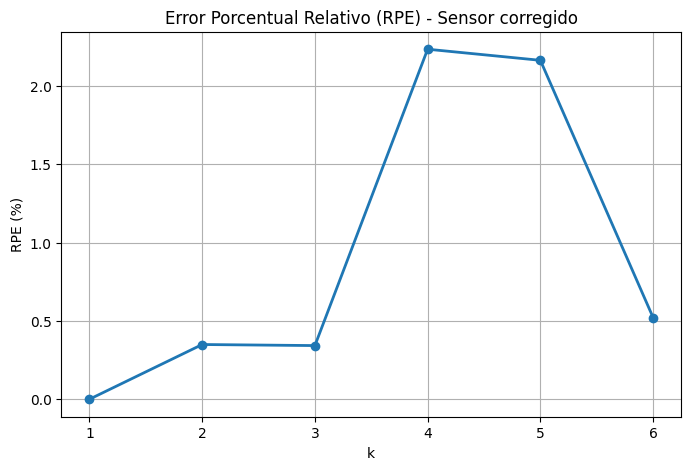

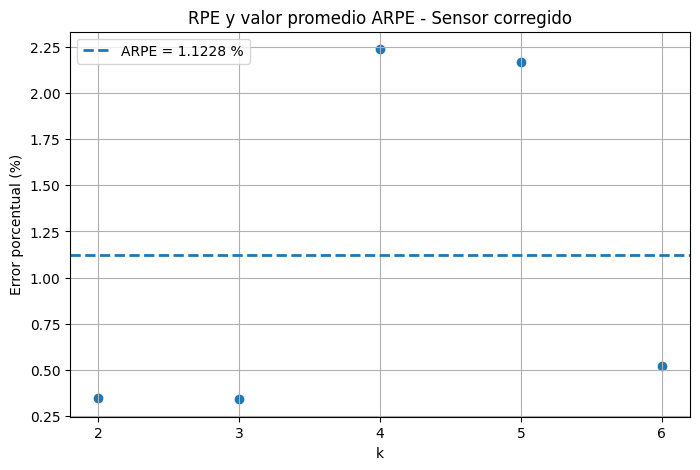

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# GRÁFICAS DE ERROR, RPE Y ARPE
# (usa `series`, `series_error`, `series_RPE` y `series_ARPE`
#  de la celda anterior)
# =========================================================

for nombre, X0 in series.items():
    error = series_error[nombre]
    RPE   = series_RPE[nombre]
    ARPE  = series_ARPE[nombre]

    # Índice temporal (solo sobre los datos reales)
    k_err = np.arange(1, len(X0) + 1)

    print(f"===== {nombre} =====")
    print("Error:")
    print(error)

    print("\nRPE (%):")
    print(RPE)

    print("\nARPE = {:.4f} %".format(ARPE))

    # -----------------------------------------------------
    # GRÁFICA 1: ERROR
    # -----------------------------------------------------
    plt.figure(figsize=(8, 5))

    plt.plot(k_err, error, marker='o', linewidth=2)
    plt.axhline(y=0, linestyle='--')

    plt.xlabel('k')
    plt.ylabel(r'Error $\varepsilon(k)$')
    plt.title(rf'Error del modelo GM(1,1) - {nombre}')

    plt.xticks(k_err)
    plt.grid(True)

    plt.show()

    # -----------------------------------------------------
    # GRÁFICA 2: RPE
    # -----------------------------------------------------
    plt.figure(figsize=(8, 5))

    plt.plot(k_err, RPE, marker='o', linewidth=2)

    plt.xlabel('k')
    plt.ylabel('RPE (%)')
    plt.title(f'Error Porcentual Relativo (RPE) - {nombre}')

    plt.xticks(k_err)
    plt.grid(True)

    plt.show()

    # -----------------------------------------------------
    # GRÁFICA 3: ARPE
    # El ARPE es un único valor, por lo que se representa
    # como una línea horizontal
    # -----------------------------------------------------
    plt.figure(figsize=(8, 5))

    plt.axhline(
        y=ARPE,
        linestyle='--',
        linewidth=2,
        label=f'ARPE = {ARPE:.4f} %'
    )

    plt.scatter(k_err[1:], RPE[1:])

    plt.xlabel('k')
    plt.ylabel('Error porcentual (%)')
    plt.title(f'RPE y valor promedio ARPE - {nombre}')

    plt.xticks(k_err[1:])
    plt.grid(True)
    plt.legend()

    plt.show()